In [1]:
import pandas as pd
import os
from glob import glob  # Pattern matching file path
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
#import tensorflow as tf

In [2]:
import dask
import dask_cuda
import cudf
import cupy
from dask.distributed import Client, LocalCluster
from dask_cuda import LocalCUDACluster
import dask_cudf
import os

# --- Configuration for Resource Usage ---
# Get total memory from nvidia-smi output (49140 MiB for RTX A6000)
# Convert MiB to Bytes: 49140 * 1024 * 1024 = 51520630784 Bytes
TOTAL_GPU_MEMORY_BYTES = 49140 * 1024 * 1024 

# Desired usage percentage
GPU_MEMORY_PERCENTAGE_TO_USE = 0.70 # 70%

# Calculate the memory limit for each worker
# LocalCUDACluster by default launches one worker per available GPU.
# So, if you have one A6000, one worker will use 70% of its memory.
DEVICE_MEMORY_LIMIT = int(TOTAL_GPU_MEMORY_BYTES * GPU_MEMORY_PERCENTAGE_TO_USE)

# You can optionally specify which GPUs to use if you have multiple
# and want to restrict to certain ones.
# For a single A6000, this is often not necessary unless you have other processes.
# CUDA_VISIBLE_DEVICES = "0" # Use only GPU 0

# --- Dask Cluster Setup ---
print(f"Setting device_memory_limit per worker to: {DEVICE_MEMORY_LIMIT / (1024**3):.2f} GB ({GPU_MEMORY_PERCENTAGE_TO_USE*100:.0f}% of total GPU memory)")

# 1. Start a Local Dask Cluster with GPU resources
# We pass the calculated device_memory_limit here.
# n_workers can be specified if you have multiple GPUs and want to use a subset.
# threads_per_worker is generally 1 for Dask-CUDA with cuDF/CuPy for best performance
# due to how CUDA streams and contexts are managed, especially if using RMM pools.
cluster = LocalCUDACluster(
    device_memory_limit=DEVICE_MEMORY_LIMIT,
    # Crucial for large workloads and preventing OOM:
    enable_cudf_spill=True, # Enable cuDF's native spilling to host if GPU memory is exhausted

    # Optional UCX for performance (requires ucx-py installed)
    protocol="ucx",
    enable_tcp_over_ucx=True,

    # threads_per_worker is generally 1 for CUDA workloads with cuDF/CuPy
    threads_per_worker=1,
)
client = Client(cluster)

print("\nDask Dashboard Link:", client.dashboard_link)
print("------------------------------------------")
print("Dask Client Info:")
print(client)
print("------------------------------------------")


Setting device_memory_limit per worker to: 33.59 GB (70% of total GPU memory)


/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 41281 instead
  warnings.warn(
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/rapids_dask_dependency/patches/distributed/comm/__rdd_patch_ucx.py:572: FutureWarning: you have requested protocol='ucx', which now defaults to UCXX but
the package 'distributed-ucxx' is not installed. The current version
of Distributed will fallback to using UCX-Py, but this fallback is
deprecated and will be removed in the next release (RAPIDS 25.10).
To silence this warning and use UCXX, install the 'distributed-ucxx'
package, or to use UCX-Py and silence the warning, use
'protocol="ucx-old"' when you create your Distributed or Dask-CUDA
cluster.                
  warnings.warn(
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/rapids_dask_dependency/patches/distr


Dask Dashboard Link: http://127.0.0.1:41281/status
------------------------------------------
Dask Client Info:
<Client: 'ucx://127.0.0.1:44235' processes=1 threads=1, memory=0.98 TiB>
------------------------------------------


2026-02-05 11:52:34,544 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 7677bfdd89584da9a5256633de079f4e initialized by task ('shuffle-transfer-7677bfdd89584da9a5256633de079f4e', 1) executed on worker ucx://127.0.0.1:57149
2026-02-05 11:52:40,975 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 7677bfdd89584da9a5256633de079f4e deactivated due to stimulus 'task-finished-1770292360.973794'
2026-02-05 12:17:43,378 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 7677bfdd89584da9a5256633de079f4e initialized by task ('shuffle-transfer-7677bfdd89584da9a5256633de079f4e', 1) executed on worker ucx://127.0.0.1:57149
2026-02-05 12:17:49,725 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 7677bfdd89584da9a5256633de079f4e deactivated due to stimulus 'task-finished-1770293869.7242575'
2026-02-05 12:18:42,114 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle ea413bd9c9ffd48bb04b64d1951aac81 initialized by task ('shuffle-transfer-ea413bd9c9ffd48

In [3]:
import random
def set_seed(seed=42):
  np.random.seed(seed) 
  random.seed(seed)
set_seed()

In [4]:
def read_from_dask(file_path,blocksize_for_read = 166444036*5):    
    df = dask_cudf.read_csv(file_path, blocksize=blocksize_for_read)
    return df

In [5]:
import dask.dataframe as dd
from dask.diagnostics import ProgressBar
def check_null(df_check,label):
    
    print(f"--- Diagnóstico de Labels Nulas ---")
    
    # 1. Conta quantas linhas têm label nula (NaN / None)
    # .isnull() funciona tanto para Dask CPU quanto para Dask-cuDF (GPU)
    null_mask = df_check[label].isnull()
    
    print("Contando linhas nulas (isso pode levar um momento)...")
    with ProgressBar():
        n_nulls = null_mask.sum().compute()
    
    total_rows = len(df_check) # Se for muito lento, pode estimar ou pular esta linha
    
    print(f"\nResultado:")
    print(f"Total de linhas: {total_rows}")
    print(f"Linhas com Label NULA: {n_nulls}")
    print(f"Porcentagem de perda: {(n_nulls/total_rows)*100:.4f}%")
    
    # 2. Se houver nulos, mostre exemplos para entender o motivo
    if n_nulls > 0:
        print("\n--- Visualizando as primeiras 5 linhas problemáticas ---")
        # Filtra apenas as ruins e traz 5 para a memória
        bad_rows = df_check[null_mask].head(5, npartitions=-1)
        print(bad_rows)
        
        print("\n--- Sugestão de Correção ---")
        print("Para remover essas linhas e seguir com o código, execute:")
        print("df_to_save = df_to_save.dropna(subset=['species_id'])")
    else:
        print("\n✅ Nenhuma label nula encontrada com .isnull().")
        print("Se o erro persistir, verifique se não há strings literais como 'NaN', 'None' ou strings vazias ''.")

In [6]:
import matplotlib.pyplot as plt # Ensure this is imported for plotting

def verify_class_distribution(df, seq_col, label_col, plot= False):

    # 1. Sequence Length Statistics (lazy dask-cudf Series/Scalars)
    print("Defining sequence length statistics computation (lazy)...")
    # Note: df['sequence_length'] is added to the Dask DataFrame here
    # This will be computed once as part of the unified graph
    df['sequence_length'] = df[seq_col].str.len()

    variance_length_dask = df['sequence_length'].var()
    max_length_dask = df['sequence_length'].max()
    min_length_dask = df['sequence_length'].min()
    mean_length_dask = df['sequence_length'].mean()

    # 2. Class Distribution (lazy dask-cudf Series)
    print("Defining class distribution computation (lazy)...")
    class_distribution_dask = df[label_col].value_counts()

    # --- Single .compute() Call for All Results ---
    print("\nExecuting all defined computations with a single dask.compute()...")
    (variance_length,
    max_length,
    min_length,
    mean_length,
    class_distribution_cudf_result) = dask.compute(variance_length_dask,
                                                    max_length_dask,
                                                    min_length_dask,
                                                    mean_length_dask,
                                                    class_distribution_dask)

    # --- Process and Print Results ---
    print("\nComputations finished. Processing results for output and plotting.")

    # Process Sequence Length Statistics
    print(f"\nMaximum sequence length: {max_length}")
    print(f"Minimum sequence length: {min_length}")
    print(f"Mean sequence length: {mean_length}")
    print(f"The variance of the lengths of values in the 'sequence' column is {variance_length}.")

    # Process Class Distribution
    class_distribution = class_distribution_cudf_result.to_pandas() # Convert cuDF Series to pandas Series
    print("\nClass distribution:")
    print(class_distribution)

    # Plot class distribution
    if plot:
        class_distribution.plot(kind='bar')
        plt.xlabel('Class')
        plt.ylabel('Frequency')
        plt.title('Class Distribution in Label Column')
        plt.tight_layout() # Adjust layout to prevent labels from overlapping
        plt.show()
    return class_distribution


In [7]:
df_dataset = read_from_dask(f"raw_database/final.csv",blocksize_for_read="100MB")


[1062260][11:51:50:105053][warning] Auto detection of compression type is supported only for file type buffers. For other buffer types, AUTO compression type assumes uncompressed input.


In [10]:
check_null(df_dataset,"species_id")

--- Diagnóstico de Labels Nulas ---
Contando linhas nulas (isso pode levar um momento)...

Resultado:
Total de linhas: 33023
Linhas com Label NULA: 8
Porcentagem de perda: 0.0242%

--- Visualizando as primeiras 5 linhas problemáticas ---
      Unnamed: 0.1  Unnamed: 0  \
1024         13523       13523   
1609         15133       15133   
1380         16514       16514   
1157         17672       17672   
1634         19307       19307   

                                               sequence species_id genus_id  \
1024  GAAATCGTCCATCATCTGAGTAACAAGGGAGGTTGTTGGAACGATT...       <NA>     <NA>   
1609  CGTGACTACCAGCATTAAGCAATGATTTGCTGATACTTCTTCCGGG...       <NA>     <NA>   
1380  ATGGGGGTATGTTCCGCGCCGGAACATAATGCTTCCCCCTCCCTAT...       <NA>     <NA>   
1157  CCGCGCATCGTGATTACTCTTCGCCTTCGTCCGCGCTCAGCCACTC...       <NA>     <NA>   
1634  ATGGCCGCCGACTATGGCGGCTTTGTTTTGCGTGTTACTATTACCA...       <NA>     <NA>   

      sequence_length  
1024            51285  
1609             6027  
1380      

Defining sequence length statistics computation (lazy)...
Defining class distribution computation (lazy)...

Executing all defined computations with a single dask.compute()...

Computations finished. Processing results for output and plotting.

Maximum sequence length: 8240007
Minimum sequence length: 3
Mean sequence length: 32742.342488568574
The variance of the lengths of values in the 'sequence' column is 10160702528.88397.

Class distribution:
species_id
6369     3
8738     2
5339     2
1043     3
178      3
        ..
7548     2
13102    2
912      3
2925     2
10125    3
Name: count, Length: 13592, dtype: int64


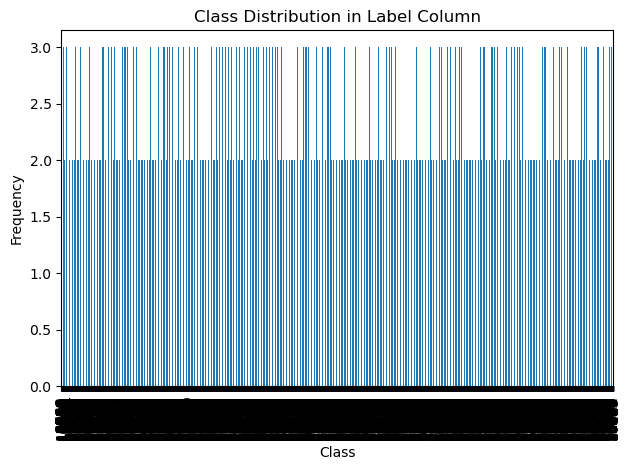

In [12]:
class_distribution = verify_class_distribution(df_dataset,"sequence","species_id",plot=True)

/tmp/ipykernel_732867/1755695205.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=subset.values, y=subset.index.astype(str), palette="viridis")


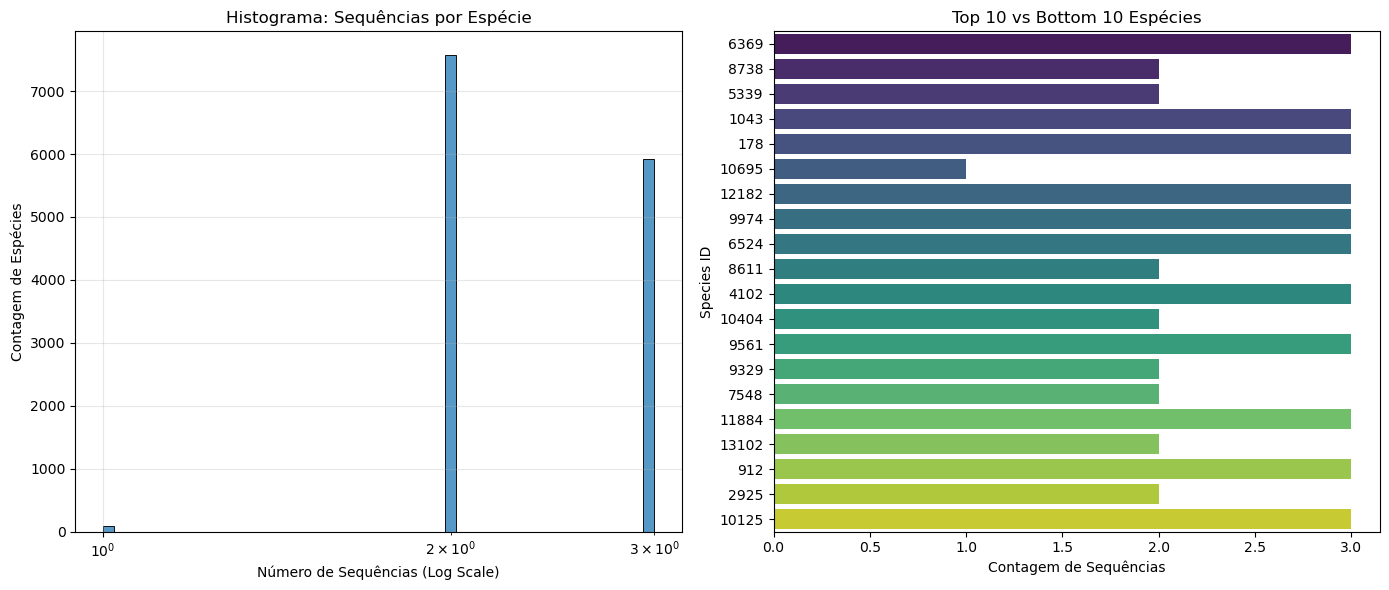

Total de Espécies: 13592
Média de seqs/espécie: 2.43
Mediana de seqs/espécie: 2.00
Máximo de seqs em uma espécie: 3
Mínimo de seqs em uma espécie: 1


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Supondo que 'class_distribution' é o resultado do seu dask.compute()
# Se precisar recalcular: 
# class_distribution = df['species_id'].value_counts().compute()

plt.figure(figsize=(14, 6))
 
# --- Gráfico 1: Histograma de Quantidade de Amostras ---
# Mostra: "Quantas espécies têm 1 sequência? Quantas têm 2? Quantas têm 100?"
plt.subplot(1, 2, 1)
sns.histplot(class_distribution.values, bins=50, kde=False, log_scale=(True, False))
plt.title("Histograma: Sequências por Espécie")
plt.xlabel("Número de Sequências (Log Scale)")
plt.ylabel("Contagem de Espécies")
plt.grid(True, alpha=0.3)

# --- Gráfico 2: As 20 Espécies com Mais e Menos Dados ---
# Ajuda a ver o desbalanceamento extremo
plt.subplot(1, 2, 2)
# Pega as 10 mais frequentes e as 10 menos frequentes
top_10 = class_distribution.head(10)
bottom_10 = class_distribution.tail(10)
subset = pd.concat([top_10, bottom_10])

sns.barplot(x=subset.values, y=subset.index.astype(str), palette="viridis")
plt.title("Top 10 vs Bottom 10 Espécies")
plt.xlabel("Contagem de Sequências")
plt.ylabel("Species ID")

plt.tight_layout()
plt.show()

# Estatísticas Numéricas Rápidas
print(f"Total de Espécies: {len(class_distribution)}")
print(f"Média de seqs/espécie: {class_distribution.mean():.2f}")
print(f"Mediana de seqs/espécie: {class_distribution.median():.2f}")
print(f"Máximo de seqs em uma espécie: {class_distribution.max()}")
print(f"Mínimo de seqs em uma espécie: {class_distribution.min()}")

Defining sequence length statistics computation (lazy)...
Defining class distribution computation (lazy)...

Executing all defined computations with a single dask.compute()...

Computations finished. Processing results for output and plotting.

Maximum sequence length: 8240007
Minimum sequence length: 3
Mean sequence length: 32742.342488568574
The variance of the lengths of values in the 'sequence' column is 10160702528.88397.

Class distribution:
genus_id
3040     3
1394    16
1230     4
302     24
62      15
        ..
611      2
2334    12
1437     3
2305     2
1384     2
Name: count, Length: 3027, dtype: int64


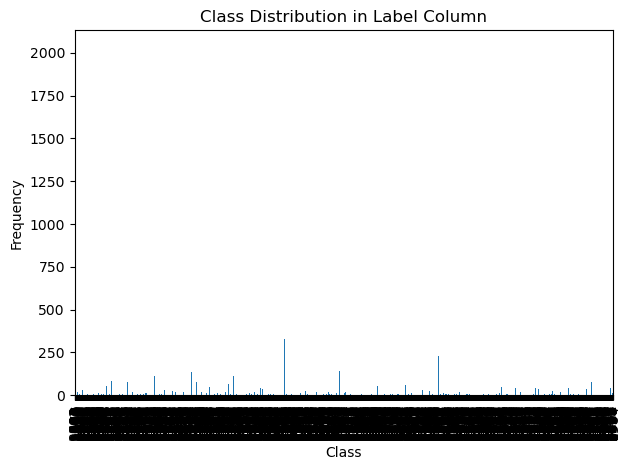

genus_id
3040     3
1394    16
1230     4
302     24
62      15
        ..
611      2
2334    12
1437     3
2305     2
1384     2
Name: count, Length: 3027, dtype: int64

In [13]:
verify_class_distribution(df_dataset,"sequence","genus_id",plot=True)

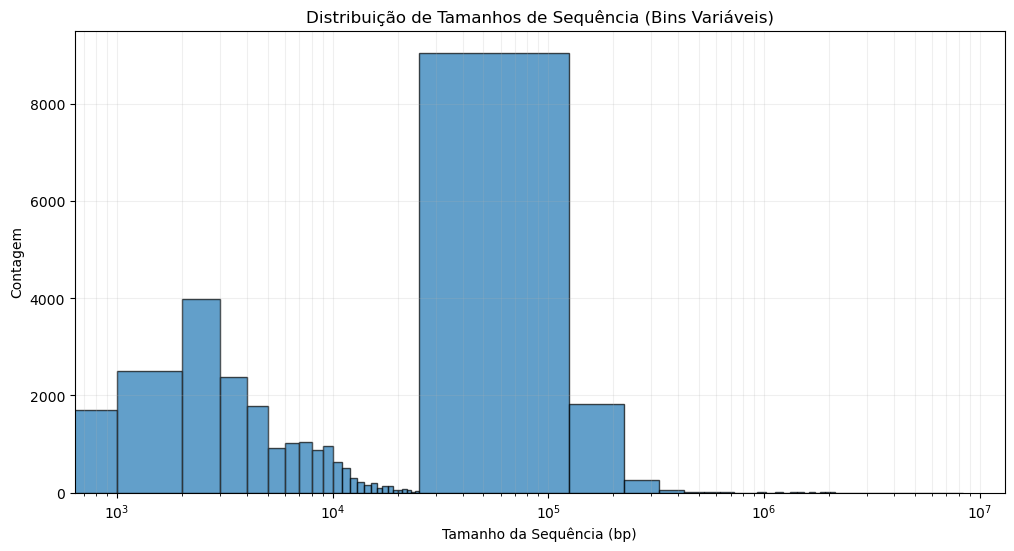

In [14]:
df = df_dataset
# 1. Calcula o tamanho das sequências (Lazy)
# Certifique-se de que 'sequence' é a coluna correta
lengths_series = df['sequence'].str.len()

# 2. Filtra menores que 500bp (conforme sua regra anterior)
lengths_series = lengths_series[lengths_series >= 500]

# 3. Computa para trazer para a RAM (apenas os números, é muito leve)
lengths = lengths_series.compute()

# 4. Define os Bins Personalizados
# Parte 1: 0 até 25k com passo de 1k
bins_small = np.arange(0, 25001, 1000)

# Parte 2: 25k até o Máximo com passo de 100k
max_len = lengths.max()
# Adicionamos um buffer ao max_len para garantir que o último bin inclua o valor máximo
bins_large = np.arange(25000, max_len + 100000, 100000)

# Combina removendo duplicatas (o 25000 aparece nos dois)
bins = np.unique(np.concatenate([bins_small, bins_large]))

# 5. Plotagem
plt.figure(figsize=(12, 6))
# Usamos o Matplotlib puro aqui pois ele lida melhor com bins de larguras diferentes que o Seaborn
plt.hist(lengths, bins=bins, edgecolor='black', alpha=0.7)

plt.title('Distribuição de Tamanhos de Sequência (Bins Variáveis)')
plt.xlabel('Tamanho da Sequência (bp)')
plt.ylabel('Contagem')

# Ajusta o eixo X para ser legível (Log scale opcional se a diferença for muito grande)
plt.xscale('log') 
plt.grid(True, which="both", ls="-", alpha=0.2)

plt.show()

In [15]:
# Quantas sequências são menores que o seu alvo máximo de simulação (10k)?
n_small = lengths[lengths < 10000].shape[0]
total = lengths.shape[0]

print(f"Sequências menores que 10k bases: {n_small} ({n_small/total:.2%})")
print("Para estas espécies, não é possível simular um read de 10k bases (será o genoma inteiro).")

Sequências menores que 10k bases: 17186 (55.26%)
Para estas espécies, não é possível simular um read de 10k bases (será o genoma inteiro).


In [16]:
df = df.dropna(subset=['species_id'])

In [14]:

from tqdm.dask import TqdmCallback

# ==============================================================================
# 1. Configurações
# ==============================================================================
MIN_SEQ_LEN = 1000
MAX_READ_LEN = 10000
OUTPUT_PATH = "./dataset_reads_sinteticos.parquet"

def calculate_n_reads(seq_len):
    if seq_len < 10000:
        return 50
    elif seq_len < 100000:
        return 200
    else:
        return 500

# ==============================================================================
# 2. Função de Processamento (Versão CPU Pura)
# ==============================================================================
def generate_reads_partition(df_partition):
    # O Dask CPU já entrega Pandas, mas por segurança checamos
    if hasattr(df_partition, "to_pandas"):
        df_partition = df_partition.to_pandas()
        
    if df_partition.empty:
        return pd.DataFrame(columns=['species_id', 'genus_id', 'origin_len', 'read_len', 'sequence'])

    generated_data = []

    for _, row in df_partition.iterrows():
        seq = row['sequence']
        seq_len = len(seq)
        sp_id = row['species_id']
        gen_id = row['genus_id']
        
        n_reads = calculate_n_reads(seq_len)
        
        for _ in range(n_reads):
            current_max_len = min(seq_len, MAX_READ_LEN)
            read_len = random.randint(MIN_SEQ_LEN, current_max_len)
            max_start = seq_len - read_len
            start_pos = random.randint(0, max_start)
            read_seq = seq[start_pos : start_pos + read_len]
            
            generated_data.append({
                'species_id': sp_id,
                'genus_id': gen_id,
                'origin_len': seq_len,
                'read_len': read_len,
                'sequence': read_seq
            })
    
    # Retorna Pandas puro (CPU)
    return pd.DataFrame(generated_data)

# ==============================================================================
# 3. Execução (MUDANÇA CRÍTICA AQUI)
# ==============================================================================

# Se 'df' foi carregado com dask_cudf (GPU), converta para Dask CPU agora.
# Isso diz ao Dask: "Processe as partições na memória RAM do sistema, não na VRAM".
if hasattr(df, "to_dask_dataframe"):
    print("Movendo grafo de execução para CPU para evitar estouro de VRAM...")
    df = df.to_dask_dataframe() 

# 1. Filtro Inicial
df_filtered = df[df['sequence'].str.len() >= MIN_SEQ_LEN]

# 2. Metadados (Pandas/NumPy types, não cuDF)
meta_dict = {
    'species_id': 'int64',
    'genus_id': 'int64',
    'origin_len': 'int64',
    'read_len': 'int64',
    'sequence': 'object'
}

df_synthetic = df_filtered.map_partitions(
    generate_reads_partition,
    meta=meta_dict
)

print("Iniciando geração de reads sintéticos (Modo CPU)...")
print("Isso pode demorar um pouco mais, mas não vai crashar a GPU.")

# Usamos engine='pyarrow' explícito para garantir escrita eficiente em CPU
with TqdmCallback(desc="Processando Partições"):
    df_synthetic.to_parquet(
        OUTPUT_PATH, 
        compression='snappy', 
        engine='pyarrow'
    )

print(f"Processo concluído! Dataset salvo em: {OUTPUT_PATH}")

Iniciando geração de reads sintéticos (Modo CPU)...
Isso pode demorar um pouco mais, mas não vai crashar a GPU.
Processo concluído! Dataset salvo em: ./dataset_reads_sinteticos.parquet


In [17]:
df_sint = dask_cudf.read_parquet(f"./dataset_reads_sinteticos.parquet", blocksize="100MB")


In [18]:
df_sint.head()

,species_id,genus_id,origin_len,read_len,sequence
0,1,1,6641,5770,TGTTATCCAGTATGTCATACCATGATTATGCCTTGGTCAGGCGAAA...
1,1,1,6641,5897,ATTCGCGCCGTCTCTTTTGGCGTTTATTCAACAGCAAAGATTGCTG...
2,1,1,6641,1826,GTTTGGTGAGACATTGGCTCTTTATGTGGTATTGCAAGGTGCGGCC...
3,1,1,6641,4475,GTGATATTTTCCGGCACTCACGTCTAACACCATTCAATTACATTAT...
4,1,1,6641,3428,ACCCTTTCAAATTGCGTTCCAAGTACTCCAGGAAAAATTTCATAAG...


In [19]:
def verificar_limites_labels(df, coluna_label='species_id'):
    print(f"Calculando min/max para a coluna: {coluna_label}...")
    
    # 1. Cria as tarefas de computação (Lazy - não roda ainda)
    tarefa_min = df[coluna_label].min()
    tarefa_max = df[coluna_label].max()
    
    # 2. Executa ambas simultaneamente (Otimizado: lê o disco apenas uma vez)
    min_val, max_val = dask.compute(tarefa_min, tarefa_max)
    
    print(f"--- Resultado ---")
    print(f"Menor Label: {min_val}")
    print(f"Maior Label: {max_val}")
    print(f"Total de Classes (Range): {max_val - min_val + 1} (se for contínuo)")
    
    return min_val, max_val

In [20]:
verificar_limites_labels(df_sint)

Calculando min/max para a coluna: species_id...
--- Resultado ---
Menor Label: 1
Maior Label: 13683
Total de Classes (Range): 13683 (se for contínuo)


(np.int64(1), np.int64(13683))

Defining sequence length statistics computation (lazy)...
Defining class distribution computation (lazy)...

Executing all defined computations with a single dask.compute()...

Computations finished. Processing results for output and plotting.

Maximum sequence length: 10000
Minimum sequence length: 1000
Mean sequence length: 4993.1382958775675
The variance of the lengths of values in the 'sequence' column is 7255199.772155048.

Class distribution:
species_id
1387      100
6289     1000
10272      50
770       150
11623     100
         ... 
274       150
1379      150
8650      400
2003      400
7994      400
Name: count, Length: 13036, dtype: int64


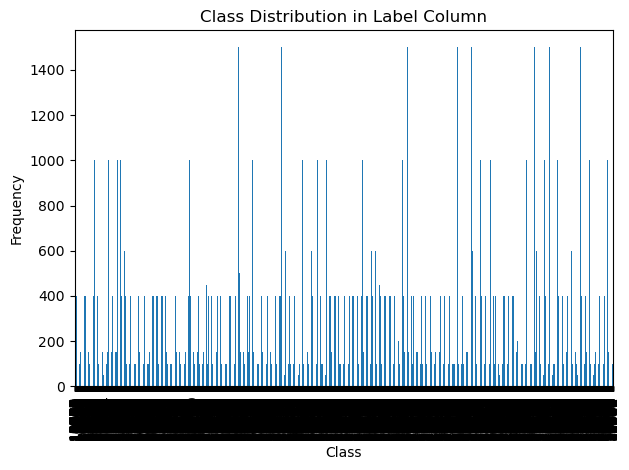

In [17]:
class_distribution = verify_class_distribution(df_sint,"sequence","species_id",plot=True)

In [21]:
check_null(df_sint,"species_id")

--- Diagnóstico de Labels Nulas ---
Contando linhas nulas (isso pode levar um momento)...

Resultado:
Total de linhas: 4351800
Linhas com Label NULA: 1300
Porcentagem de perda: 0.0299%

--- Visualizando as primeiras 5 linhas problemáticas ---
       species_id genus_id  origin_len  read_len  \
333850       <NA>     <NA>       51285      3205   
333851       <NA>     <NA>       51285      6137   
333852       <NA>     <NA>       51285      3338   
333853       <NA>     <NA>       51285      1679   
333854       <NA>     <NA>       51285      4279   

                                                 sequence  
333850  GAAAACAGATTTGACTGATGCATATCGTGAGTACAACTACGCAATG...  
333851  GTGTTTGATTCGGAAGAGGTTGCGTTTGAGGCAGCCAATCAATGTT...  
333852  AGAGACAGATATCCATCCAAGTAAAACACTGGTATGTATTAGTGAC...  
333853  GTAGAAAATTTGGAAATCGCGGATTTTATGAGAATGCACCCTGTTG...  
333854  GGTTGGTCAAGATGGTTGGAAAGGATTTCTGAGGGGTTCTGTTGAG...  

--- Sugestão de Correção ---
Para remover essas linhas e seguir com o código, execu

In [19]:
import dask.dataframe as dd
import pandas as pd
import re

# ==============================================================================
# CONFIGURAÇÃO
# ==============================================================================
INPUT_PATH = "./dataset_reads_sinteticos.parquet"

# Regex: [^ACGTacgt]
# Significa: "Encontre qualquer coisa que NÃO (^) seja A, C, G, T (maiúsculo ou minúsculo)"
INVALID_PATTERN = r'[^ACGTacgt]'

# ==============================================================================
# FUNÇÕES DE VERIFICAÇÃO
# ==============================================================================

def check_invalid_chars(df_partition):
    """
    Retorna apenas as linhas que contêm caracteres inválidos.
    """
    # str.contains com regex=True busca o padrão. 
    # Retorna True se achar algo diferente de ACGT.
    mask = df_partition['sequence'].str.contains(INVALID_PATTERN, regex=True, na=False)
    return df_partition[mask]

def extract_unique_bad_chars(series):
    """
    Função auxiliar para descobrir QUAIS são os caracteres ruins.
    """
    # Pega todos os caracteres que batem com o regex (retorna listas)
    found_lists = series.str.findall(INVALID_PATTERN)
    
    # Achata a lista de listas e pega únicos
    unique_chars = set()
    for l in found_lists:
        if isinstance(l, list):
            unique_chars.update(l)
    return list(unique_chars)
    
def run_check(INPUT_PATH):

    print("Carregando dataset...")
    df = dd.read_parquet(INPUT_PATH, engine='pyarrow')
    
    print("Procurando por sequências com caracteres inválidos (diferentes de A,C,T,G)...")
    
    # 1. Filtra as linhas inválidas (Lazy evaluation)
    # map_partitions é usado aqui para aplicar a lógica de filtro pedaço por pedaço
    invalid_rows_dask = df.map_partitions(check_invalid_chars)
    
    # 2. Computa para trazer os resultados para a memória (apenas os erros)
    # Se houver poucos erros, isso será rápido e leve.
    try:
        invalid_df = invalid_rows_dask.compute()
        
        total_invalid = len(invalid_df)
        total_samples = len(df)
        
        print(f"\n--- RELATÓRIO DE INTEGRIDADE ---")
        
        if total_invalid == 0:
            print("✅ SUCESSO! Nenhuma sequência contém caracteres inválidos. O dataset é puro (A, C, T, G).")
        else:
            print(f"⚠️ ATENÇÃO! Foram encontradas sequências com caracteres inválidos.")
            print(f"Total de sequências afetadas: {total_invalid} de {total_samples} ({total_invalid/total_samples:.4%})")
            
            # Descobre quais caracteres são esses
            bad_chars = extract_unique_bad_chars(invalid_df['sequence'])
            print(f"Caracteres estranhos encontrados: {bad_chars}")
            
            print("\nExemplos de sequências com problemas:")
            print(invalid_df[['species_id', 'sequence']].head())
    
            # Opcional: Se quiser remover essas linhas do dataset original
            # print("\nPara remover use: df_clean = df[~df['sequence'].str.contains(r'[^ACGTacgt]', regex=True)]")
    
    except Exception as e:
        print(f"Erro ao processar: {e}")

run_check(INPUT_PATH)

Carregando dataset...
Procurando por sequências com caracteres inválidos (diferentes de A,C,T,G)...

--- RELATÓRIO DE INTEGRIDADE ---
⚠️ ATENÇÃO! Foram encontradas sequências com caracteres inválidos.
Total de sequências afetadas: 102344 de 4351800 (2.3518%)
Caracteres estranhos encontrados: ['D', 'W', 'V', 'R', 'B', 'M', 'H', 'S', 'N', 'Y', 'K']

Exemplos de sequências com problemas:
      species_id                                           sequence
2002        19.0  CTAAATTGGCAGTCACGATCAGTGACTTAGCCCTTCCTTCTTTTAT...
2009        19.0  ATGGACAACGGGTTATTGATTTTTACCCTTTTTTGGTTCGAGCTTT...
2010        19.0  TTTCAGGTCTTGTTTCAAAAATGGAAACCCTCTGACCGGGGTTTCC...
2012        19.0  TGTTGATTACAGCGTTTATGTGGTTTTTGGTGGTGGCTTGCCTAGT...
2013        19.0  ACTGGTCTGGGTATGCCGTGTTTCACGACAGAGATCGGTTGATAGG...


In [34]:
import dask.dataframe as dd
import pandas as pd
import numpy as np
import random
df_to_save = df_sint
# ==============================================================================
# DICIONÁRIO IUPAC (Regras de Substituição)
# ==============================================================================
# Mapeia o código ambíguo para as opções válidas
IUPAC_RULES = {
    'R': ['A', 'G'],
    'Y': ['C', 'T'],
    'S': ['G', 'C'],
    'W': ['A', 'T'],
    'K': ['G', 'T'],
    'M': ['A', 'C'],
    'B': ['C', 'G', 'T'],
    'D': ['A', 'G', 'T'],
    'H': ['A', 'C', 'T'],
    'V': ['A', 'C', 'G'],
    'N': ['A', 'C', 'G', 'T'],
    # Adicionando minúsculas por garantia
    'n': ['A', 'C', 'G', 'T']
}

def impute_sequence(sequence):
    """
    Percorre a sequência. Se encontrar uma letra que não seja A, C, G, T,
    substitui por uma das opções válidas baseadas na regra IUPAC.
    """
    # Se a sequência for pura, retorna rápido (otimização)
    if all(c in 'ACGTacgt' for c in sequence):
        return sequence
    
    # Se tiver sujeira, reconstrói (isso é mais lento, mas necessário)
    new_seq = []
    for char in sequence:
        upper_char = char.upper()
        if upper_char in ['A', 'C', 'G', 'T']:
            new_seq.append(char)
        elif upper_char in IUPAC_RULES:
            # Escolhe aleatoriamente uma das opções válidas
            # Ex: Se for 'R', sorteia entre 'A' e 'G'
            replacement = random.choice(IUPAC_RULES[upper_char])
            new_seq.append(replacement)
        else:
            # Se for um caractere totalmente desconhecido, joga uma base aleatória
            new_seq.append(random.choice(['A', 'C', 'G', 'T']))
            
    return "".join(new_seq)

def clean_partition(df):
    """
    Função de limpeza Híbrida.
    Força a conversão para CPU (Pandas) antes de processar strings complexas.
    """
    # 1. CRÍTICO: Move os dados da VRAM (GPU) para RAM (CPU)
    # Se não fizer isso, o cuDF tenta compilar o Python e falha.
    if hasattr(df, "to_pandas"):
        df = df.to_pandas()
        
    # 2. Proteção contra partições vazias
    if df.empty:
        return df

    # 3. Aplica a lógica (Agora rodando em CPU pura, onde Python funciona bem)
    df['sequence'] = df['sequence'].apply(impute_sequence)
    
    return df

# ==============================================================================
# EXECUÇÃO BLINDADA
# ==============================================================================

print("Iniciando imputação de bases (Modo Híbrido GPU -> CPU)...")

# Precisamos criar um 'meta' que seja Pandas (CPU), não cuDF
# Pegamos uma amostra ou usamos o meta existente convertido
meta_template = df_to_save._meta.to_pandas() if hasattr(df_to_save._meta, "to_pandas") else df_to_save._meta

# Executa o map_partitions
df_imputed = df_to_save.map_partitions(
    clean_partition, 
    meta=meta_template # Informa ao Dask que o resultado é um DataFrame Pandas
)

# Salva diretamente usando engine CPU (PyArrow)
print(f"Salvando dataset limpo em: {OUTPUT_CLEAN_PATH}")
from tqdm.dask import TqdmCallback

with TqdmCallback(desc="Imputando e Salvando"):
    df_imputed.to_parquet(
        OUTPUT_CLEAN_PATH, 
        compression='snappy', 
        engine='pyarrow' # Essencial: usa o motor de escrita da CPU
    )

print("✅ Processo concluído sem erros de compilação CUDA.")


Iniciando imputação de bases (Modo Híbrido GPU -> CPU)...
Salvando dataset limpo em: ./dataset_reads_sinteticos_CLEAN.parquet
✅ Processo concluído sem erros de compilação CUDA.


In [ ]:
run_check(OUTPUT_CLEAN_PATH)

In [23]:
INPUT_PATH=f"./dataset_reads_sinteticos_CLEAN.parquet"
df_sint_clean = dask_cudf.read_parquet(INPUT_PATH, blocksize="100MB")


In [36]:
df_sint_clean.head()

,species_id,genus_id,origin_len,read_len,sequence
0,1,1,6641,5770,TGTTATCCAGTATGTCATACCATGATTATGCCTTGGTCAGGCGAAA...
1,1,1,6641,5897,ATTCGCGCCGTCTCTTTTGGCGTTTATTCAACAGCAAAGATTGCTG...
2,1,1,6641,1826,GTTTGGTGAGACATTGGCTCTTTATGTGGTATTGCAAGGTGCGGCC...
3,1,1,6641,4475,GTGATATTTTCCGGCACTCACGTCTAACACCATTCAATTACATTAT...
4,1,1,6641,3428,ACCCTTTCAAATTGCGTTCCAAGTACTCCAGGAAAAATTTCATAAG...


In [24]:
verificar_limites_labels(df_sint_clean)

Calculando min/max para a coluna: species_id...
--- Resultado ---
Menor Label: 1
Maior Label: 13683
Total de Classes (Range): 13683 (se for contínuo)


(np.int64(1), np.int64(13683))

In [25]:


# Defina aqui qual DataFrame você quer checar (df_sint_clean ou df_to_save)
check_null(df_sint_clean,"species_id")


--- Diagnóstico de Labels Nulas ---
Contando linhas nulas (isso pode levar um momento)...

Resultado:
Total de linhas: 4351800
Linhas com Label NULA: 1300
Porcentagem de perda: 0.0299%

--- Visualizando as primeiras 5 linhas problemáticas ---
       species_id genus_id  origin_len  read_len  \
333850       <NA>     <NA>       51285      3205   
333851       <NA>     <NA>       51285      6137   
333852       <NA>     <NA>       51285      3338   
333853       <NA>     <NA>       51285      1679   
333854       <NA>     <NA>       51285      4279   

                                                 sequence  
333850  GAAAACAGATTTGACTGATGCATATCGTGAGTACAACTACGCAATG...  
333851  GTGTTTGATTCGGAAGAGGTTGCGTTTGAGGCAGCCAATCAATGTT...  
333852  AGAGACAGATATCCATCCAAGTAAAACACTGGTATGTATTAGTGAC...  
333853  GTAGAAAATTTGGAAATCGCGGATTTTATGAGAATGCACCCTGTTG...  
333854  GGTTGGTCAAGATGGTTGGAAAGGATTTCTGAGGGGTTCTGTTGAG...  

--- Sugestão de Correção ---
Para remover essas linhas e seguir com o código, execu

In [27]:
import dask_cudf
import dask.dataframe as dd
import dask.array as da
import os
from dask.distributed import Client
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split as sk_train_test_split
from dask.diagnostics import ProgressBar
import dask
import cudf
import warnings

warnings.filterwarnings("ignore", message="Sending large graph.*")

# --- Parâmetros ---
NUM_PARTITIONS_TO_SAVE = 256
output_dir = "processed_ncbi_splited_parquet"
train_dir = os.path.join(output_dir, "train")
test_dir = os.path.join(output_dir, "test")
val_dir = os.path.join(output_dir, "validation")

# Caminhos para salvar os novos dicionários (Esses são os arquivos de ouro!)
species_map_path = "mapping_species_final.csv"
genus_map_path = "mapping_genus_final.csv"

# --- 0. Carregamento e Limpeza ---
try:
    # Assumindo que df_sint_clean já existe na memória ou foi carregado
    df_to_save = df_sint_clean
    
    # IMPORTANTE: Removemos linhas onde Species OU Genus são nulos
    # para garantir integridade nos dois níveis taxonômicos
    df_to_save = df_to_save.dropna(subset=['species_id', 'genus_id'])
    
except NameError:
    raise NameError("A variável 'df_sint_clean' não está definida.")

print("--- 1. Gerando Mapeamentos e Salvando Dicionários ---")

# Função auxiliar para gerar mapa, salvar CSV e retornar objeto para broadcast
def process_and_save_mapping(df, col_name, csv_output_path):
    print(f"Processando coluna: {col_name}...")
    
    # 1. Coleta únicos (traz para memória da GPU/CPU local)
    with ProgressBar():
        unique_labels = df[col_name].unique().compute()
    
    # 2. ORDENAÇÃO (Crucial: Define quem será o índice 0, 1, 2...)
    unique_labels_sorted = unique_labels.sort_values()
    
    # 3. Criação dos índices novos (0..N)
    # map_keys = ID Original (TaxID)
    # map_values = Novo Índice (0, 1, 2...)
    map_keys = unique_labels_sorted.values
    new_indices = range(len(map_keys))
    
    # Cria a Series para o cudf.map (Key=Original, Value=Novo)
    mapping_series = cudf.Series(new_indices, index=map_keys)
    
    # 4. SALVA O GABARITO (CSV)
    # Convertemos para Pandas para salvar em disco fácil
    df_map_export = pd.DataFrame({
        'tax_id_original': unique_labels_sorted.to_pandas(), # Coluna 1
        'new_model_label': new_indices                       # Coluna 2
    })
    
    df_map_export.to_csv(csv_output_path, index=False)
    print(f"✅ Dicionário salvo em: {csv_output_path} ({len(df_map_export)} classes)")
    
    return mapping_series, len(df_map_export)

# --- 1.1 Processar Species ---
map_series_species, num_classes_species = process_and_save_mapping(
    df_to_save, 'species_id', species_map_path
)

# --- 1.2 Processar Genus ---
map_series_genus, num_classes_genus = process_and_save_mapping(
    df_to_save, 'genus_id', genus_map_path
)

# --- 1.3 Broadcast e Aplicação ---
print("Espalhando mapas para os workers (Broadcast)...")
# Se estiver usando Client distribuído:
# client = Client() # Descomente se não tiver instanciado antes
map_species_b = client.scatter(map_series_species, broadcast=True)
map_genus_b = client.scatter(map_series_genus, broadcast=True)

def apply_all_mappings(partition, map_sp, map_gn):
    # Aplica o map nas duas colunas
    partition['species_id'] = partition['species_id'].map(map_sp)
    partition['genus_id'] = partition['genus_id'].map(map_gn)
    
    # Garante tipo inteiro (opcional, mas bom para economizar memória)
    partition['species_id'] = partition['species_id'].astype('int32')
    partition['genus_id'] = partition['genus_id'].astype('int32')
    
    return partition

print("Aplicando remapeamento nas partições...")
df_remapped = df_to_save.map_partitions(
    apply_all_mappings,
    map_sp=map_species_b,
    map_gn=map_genus_b,
    meta=df_to_save._meta
)

# --- 2. Embaralhamento (Shuffle) ---
print("\n--- 2. Embaralhamento e Reparticionamento ---")
SEED = 42
meta_with_random = df_remapped._meta.assign(random_idx=np.float32())

def add_random_idx_partition(part, partition_info=None, seed=SEED):
    part_num = partition_info["number"] if partition_info is not None else 0
    rng = np.random.RandomState(seed + int(part_num))
    rnd = rng.random_sample(len(part)).astype(np.float32)
    
    if isinstance(part, cudf.DataFrame):
        part["random_idx"] = cudf.Series(rnd)
    else:
        part["random_idx"] = rnd
    return part

df_with_random = df_remapped.map_partitions(
    add_random_idx_partition, meta=meta_with_random, partition_info=True
)

df_shuffled = df_with_random.shuffle(
    on="random_idx", npartitions=NUM_PARTITIONS_TO_SAVE
).drop(columns="random_idx")

df_to_save = df_shuffled

# --- 3. Estratificação (Baseada em SPECIES) ---
print("\n--- 3. Gerando Splits Estratificados (por Espécie) ---")
# Traz labels para memória para usar train_test_split do sklearn
with ProgressBar():
    all_labels_pandas = df_to_save['species_id'].compute().to_pandas()

# Verificação de classes raras
label_counts = all_labels_pandas.value_counts()
MIN_SAMPLES = 3
valid_classes = label_counts[label_counts >= MIN_SAMPLES].index

if len(valid_classes) < len(label_counts):
    print(f"⚠️ Removendo {len(label_counts) - len(valid_classes)} classes com < 3 amostras.")
    # Filtra localmente os índices
    mask_valid = all_labels_pandas.isin(valid_classes)
    all_labels_pandas = all_labels_pandas[mask_valid]
    
    # IMPORTANTE: Temos que filtrar o Dask Dataframe também!
    # Mas como filtrar por índice no Dask depois de um Shuffle é difícil,
    # geralmente filtramos ANTES. Mas para seguir seu fluxo, vamos filtrar por isin
    # Nota: Isso pode ser pesado se valid_classes for gigante, mas é o jeito seguro.
    # Se quiser otimizar: faça a limpeza de raras ANTES de remapear as IDs lá no começo.
    
    # Convertendo valid_classes para lista simples para o query/isin do dask
    valid_classes_list = valid_classes.tolist()
    df_to_save = df_to_save[df_to_save['species_id'].isin(valid_classes_list)]

# Split dos índices
indices = np.arange(len(all_labels_pandas))
train_idx, temp_idx, _, temp_lbl = sk_train_test_split(
    indices, all_labels_pandas, test_size=0.2, stratify=all_labels_pandas, random_state=42
)
test_idx, val_idx, _, _ = sk_train_test_split(
    temp_idx, temp_lbl, test_size=0.5, stratify=temp_lbl, random_state=42
)

# --- 4. Mapear Splits de volta para Partições ---
print("Calculando offsets globais...")
with ProgressBar():
    partition_lengths = df_to_save.map_partitions(len).compute()
global_offsets = np.cumsum([0] + list(partition_lengths)[:-1])

# Ordena índices para busca rápida
train_idx.sort()
test_idx.sort()
val_idx.sort()

# Scatter
train_idx_b = client.scatter(train_idx, broadcast=True)
test_idx_b = client.scatter(test_idx, broadcast=True)
val_idx_b = client.scatter(val_idx, broadcast=True)
global_offsets_b = client.scatter(global_offsets, broadcast=True)

def get_partitions_by_sorted_indices(partition, partition_info, sorted_indices_to_keep, global_offsets):
    p_num = partition_info['number']
    p_start = global_offsets[p_num]
    p_end = p_start + len(partition)
    
    # Busca binária
    start_pos = np.searchsorted(sorted_indices_to_keep, p_start, side='left')
    end_pos = np.searchsorted(sorted_indices_to_keep, p_end, side='left')
    
    # Índices globais que caem nesta partição
    wanted_global = sorted_indices_to_keep[start_pos:end_pos]
    
    # Converte para local
    local_indices = wanted_global - p_start
    return partition.iloc[local_indices]

meta = df_to_save._meta
df_train = df_to_save.map_partitions(get_partitions_by_sorted_indices, sorted_indices_to_keep=train_idx_b, global_offsets=global_offsets_b, meta=meta, partition_info=True)
df_test = df_to_save.map_partitions(get_partitions_by_sorted_indices, sorted_indices_to_keep=test_idx_b, global_offsets=global_offsets_b, meta=meta, partition_info=True)
df_val = df_to_save.map_partitions(get_partitions_by_sorted_indices, sorted_indices_to_keep=val_idx_b, global_offsets=global_offsets_b, meta=meta, partition_info=True)

# --- 5. Salvar ---
print("\n--- 5. Salvando Parquets ---")
os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

# Reparticiona para garantir tamanho uniforme
df_train = df_train.repartition(npartitions=NUM_PARTITIONS_TO_SAVE)
df_test = df_test.repartition(npartitions=NUM_PARTITIONS_TO_SAVE)
df_val = df_val.repartition(npartitions=NUM_PARTITIONS_TO_SAVE)

with ProgressBar():
    dask.compute(
        df_train.to_parquet(train_dir, overwrite=True),
        df_test.to_parquet(test_dir, overwrite=True),
        df_val.to_parquet(val_dir, overwrite=True)
    )

print(f"\n🎉 Processo Concluído!")
print(f"Mapas salvos em:\n  - {species_map_path}\n  - {genus_map_path}")
print(f"Dados salvos em:\n  - {train_dir}\n  - {test_dir}\n  - {val_dir}")

--- 1. Gerando Mapeamentos e Salvando Dicionários ---
Processando coluna: species_id...
✅ Dicionário salvo em: mapping_species_final.csv (13036 classes)
Processando coluna: genus_id...
✅ Dicionário salvo em: mapping_genus_final.csv (2988 classes)
Espalhando mapas para os workers (Broadcast)...
Aplicando remapeamento nas partições...

--- 2. Embaralhamento e Reparticionamento ---

--- 3. Gerando Splits Estratificados (por Espécie) ---
Calculando offsets globais...

--- 5. Salvando Parquets ---

🎉 Processo Concluído!
Mapas salvos em:
  - mapping_species_final.csv
  - mapping_genus_final.csv
Dados salvos em:
  - processed_ncbi_splited_parquet/train
  - processed_ncbi_splited_parquet/test
  - processed_ncbi_splited_parquet/validation


In [46]:
import dask_cudf
import os
import cudf
import cupy as cp

def verify_dataset(data_path: str, expected_length: int = 512):
    """
    Verifica a integridade de um conjunto de dados particionado em Parquet.

    Args:
        data_path (str): Caminho para o diretório do dataset (e.g., './processed/train').
        expected_length (int): O tamanho esperado da sequência.
    """
    print(f"\n--- Verificando o dataset em: {data_path} ---")
    
    try:
        ddf = dask_cudf.read_parquet(data_path, engine='cudf')
        print(f"Dataset lido com sucesso. Total de partições: {ddf.npartitions}")
        print(f"Total de amostras no dataset: {len(ddf):,}")
    except Exception as e:
        print(f"ERRO: Não foi possível ler o dataset de {data_path}. Erro: {e}")
        return

    if 'sequence' not in ddf.columns:
        print("FALHA: A coluna 'sequence' não foi encontrada.")
        return

    # 1. Verificar o comprimento de todas as strings na coluna
    print("\nVerificando o comprimento da coluna 'sequence'...")
    try:
        sequence_lengths = ddf['sequence'].str.len()
        max_len = sequence_lengths.max().compute()
        min_len = sequence_lengths.min().compute()
        mean_len = sequence_lengths.mean().compute()
        variance = sequence_lengths.var().compute()
        
        print(f"Comprimento MÁXIMO da sequência: {max_len}")
        print(f"Comprimento MÍNIMO da sequência: {min_len}")
        print(f"Comprimento MÉDIO da sequência: {mean_len:.2f}")
        print(f"VARIANÇA do comprimento: {variance:.2f}")
        max_label = ddf['species_id'].max().compute()
        min_label = ddf['species_id'].min().compute()
        print(f"label MÁXIMA: {max_label}")
        print(f"label MÍNIMA: {min_label}")
        
        if max_len == expected_length and min_len == expected_length:
            print("SUCESSO: Todas as sequências têm o comprimento correto de 512 caracteres.")
        else:
            print(f"FALHA: Comprimentos de sequência inconsistentes. Esperado: {expected_length}, Encontrado: Min={min_len}, Max={max_len}")
            return
            
    except Exception as e:
        print(f"ERRO: Falha ao verificar o comprimento das sequências. Erro: {e}")
        return
        
    # --- NOVO: Lógica de Verificação de Caracteres Corrigida ---
    print("\nVerificando se há caracteres inesperados...")
    
    # Criar uma expressão regular para caracteres que NÃO são válidos
    # A negação `[^...]` na regex encontra qualquer caractere que não esteja no conjunto
    invalid_chars_regex = r'[^ACGT_]'
    
    try:
        # Usa .str.contains para encontrar strings com caracteres inválidos
        # .any() retorna True se alguma partição tiver uma correspondência
        has_invalid_chars = ddf['sequence'].str.contains(invalid_chars_regex).any().compute()
    
        if not has_invalid_chars:
            print("SUCESSO: Nenhum caractere inesperado encontrado.")
        else:
            print("FALHA: Caracteres inesperados foram encontrados na coluna 'sequence.")

    except Exception as e:
        print(f"ERRO: Falha ao verificar caracteres inválidos. Erro: {e}")
        return

    # 4. Exibir uma amostra dos dados
    print("\nMostrando uma amostra das primeiras 5 linhas...")
    try:
        sample_df = ddf.head(5).to_pandas()
        print(sample_df[['sequence', 'species_id']])
    except Exception as e:
        print(f"ERRO: Falha ao exibir a amostra dos dados. Erro: {e}")

# --- Execução da verificação para cada split ---
base_dir = f"./processed_ncbi_splited_parquet"
verify_dataset(os.path.join(base_dir, 'train'))
verify_dataset(os.path.join(base_dir, 'test'))
verify_dataset(os.path.join(base_dir, 'validation'))


--- Verificando o dataset em: ./processed_ncbi_splited_parquet/train ---
Dataset lido com sucesso. Total de partições: 256
Total de amostras no dataset: 3,480,400

Verificando o comprimento da coluna 'sequence'...
Comprimento MÁXIMO da sequência: 10000
Comprimento MÍNIMO da sequência: 1000
Comprimento MÉDIO da sequência: 4993.40
VARIANÇA do comprimento: 7255556.21
label MÁXIMA: 13035
label MÍNIMA: 0
FALHA: Comprimentos de sequência inconsistentes. Esperado: 512, Encontrado: Min=1000, Max=10000

--- Verificando o dataset em: ./processed_ncbi_splited_parquet/test ---
Dataset lido com sucesso. Total de partições: 256
Total de amostras no dataset: 435,050

Verificando o comprimento da coluna 'sequence'...
Comprimento MÁXIMO da sequência: 10000
Comprimento MÍNIMO da sequência: 1000
Comprimento MÉDIO da sequência: 5000.65
VARIANÇA do comprimento: 7250887.31
label MÁXIMA: 13035
label MÍNIMA: 0
FALHA: Comprimentos de sequência inconsistentes. Esperado: 512, Encontrado: Min=1000, Max=10000

--

In [28]:
!pwd

/home/mlima/workspace/lstm-cnn


In [33]:
import pandas as pd

# ==============================================================================
# 1. Configuração
# ==============================================================================
arquivo_csv = "raw_database/final.csv"  # Substitua pelo nome real
coluna_especie = 'species_id'
coluna_genero = 'genus_id'

print(f"Lendo colunas de taxonomia do CSV: {arquivo_csv}...")

# ==============================================================================
# 2. Leitura Otimizada (usecols)
# ==============================================================================
try:
    # 'usecols' carrega SOMENTE as colunas que importam, tornando a leitura muito leve
    df = pd.read_csv(arquivo_csv, usecols=[coluna_especie, coluna_genero])
    
    print(f"Linhas totais lidas: {len(df)}")
    
    # Remove linhas com valores nulos (se houver sujeira)
    df = df.dropna()

    # ==============================================================================
    # 3. Extração da Relação Única (De-Para)
    # ==============================================================================
    print("Extraindo pares únicos Espécie <-> Gênero...")
    
    # drop_duplicates() aqui garante que teremos apenas 1 linha para cada espécie
    # mantendo a coluna do gênero correspondente
    df_taxonomia = df.drop_duplicates(subset=[coluna_especie, coluna_genero])
    
    # Ordena pelo ID da espécie
    df_taxonomia = df_taxonomia.sort_values(by=coluna_especie).reset_index(drop=True)
    
    print(f"Total de espécies únicas identificadas: {len(df_taxonomia)}")

    # ==============================================================================
    # 4. Verificação de Integridade (Sanity Check)
    # ==============================================================================
    # Verifica se alguma espécie está ligada a mais de um gênero (o que seria um erro biológico/dados)
    contagem_generos = df_taxonomia.groupby(coluna_especie).size()
    duplicados = contagem_generos[contagem_generos > 1]
    
    if not duplicados.empty:
        print(f"\n⚠️ ALERTA CRÍTICO: Encontradas {len(duplicados)} espécies associadas a múltiplos gêneros!")
        print("Exemplo de IDs problemáticos:", duplicados.index[:5].tolist())
        # Mostra as linhas problemáticas
        print(df_taxonomia[df_taxonomia[coluna_especie].isin(duplicados.index[:5])])
    else:
        print("\n✅ Sucesso: Hierarquia consistente (1 Espécie -> 1 Gênero).")
        
        # Salva o resultado limpo
        saida_csv = "mapeamento_especie_genero.csv"
        df_taxonomia.to_csv(saida_csv, index=False)
        print(f"Mapeamento salvo em: {saida_csv}")
        print(df_taxonomia.head())

except ValueError as e:
    print(f"Erro: Verifique se os nomes das colunas estão corretos. {e}")
except FileNotFoundError:
    print("Erro: Arquivo CSV não encontrado.")

Lendo colunas de taxonomia do CSV: raw_database/final.csv...
Linhas totais lidas: 33023
Extraindo pares únicos Espécie <-> Gênero...
Total de espécies únicas identificadas: 13592

✅ Sucesso: Hierarquia consistente (1 Espécie -> 1 Gênero).
Mapeamento salvo em: mapeamento_especie_genero.csv
   species_id  genus_id
0           1         1
1           2         1
2           3         1
3           4         1
4           5         1
